# Bitacora procesamiento del dataset

## Paso 0: Carga y exploracion inicial
Se lee el archivo original sin modificarlo y se revisa su estructura.

In [1]:
import pandas as pd

df_original = pd.read_csv("Argentina_Con_Gestion.csv", sep=";")
df_original.head()

,CNT,STRATUM,CNTSCHID,CNTSTUID,W_FSTUWT,ESCS,PV1MATH,PV1READ,GEST
0,ARG,ARG01,3200001,3200001,11.337040,-1.222751,459.589711,510.650824,0
1,ARG,ARG01,3200001,3200002,9.872573,-1.479476,341.782875,326.301510,0
2,ARG,ARG01,3200001,3200003,9.872573,-1.695081,439.234975,513.795472,0
3,ARG,ARG01,3200001,3200004,13.706017,-0.381331,322.605331,214.364471,0
4,ARG,ARG01,3200001,3200005,9.872573,0.193281,414.069409,381.937331,0


In [2]:
print("Filas y columnas:", df_original.shape)
df_original.info()

Filas y columnas: (11092, 9)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11092 entries, 0 to 11091
Data columns (total 9 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   CNT       11092 non-null  object 
 1   STRATUM   11092 non-null  object 
 2   CNTSCHID  11092 non-null  int64  
 3   CNTSTUID  11092 non-null  int64  
 4   W_FSTUWT  11092 non-null  float64
 5   ESCS      9808 non-null   float64
 6   PV1MATH   11092 non-null  float64
 7   PV1READ   11092 non-null  float64
 8   GEST      11092 non-null  int64  
dtypes: float64(4), int64(3), object(2)
memory usage: 780.0+ KB


In [3]:
print("Faltantes por columna:")
print(df_original.isna().sum())

print("\nFilas duplicadas:", df_original.duplicated().sum())
print("¿id de estudiante unico?", df_original["CNTSTUID"].is_unique)
print("Estratos:", df_original["STRATUM"].nunique())
print("Escuelas:", df_original["CNTSCHID"].nunique())

Faltantes por columna:
CNT            0
STRATUM        0
CNTSCHID       0
CNTSTUID       0
W_FSTUWT       0
ESCS        1284
PV1MATH        0
PV1READ        0
GEST           0
dtype: int64

Filas duplicadas: 0
¿id de estudiante unico? True
Estratos: 20
Escuelas: 412


In [4]:
df_original[["ESCS", "PV1MATH", "PV1READ", "W_FSTUWT"]].describe()

,ESCS,PV1MATH,PV1READ,W_FSTUWT
count,9808.000000,11092.000000,11092.000000,11092.000000
mean,-0.498775,383.631053,402.699029,54.908999
std,1.049204,81.391024,92.040096,52.224929
min,-4.090344,118.606638,77.510992,7.931228
25%,-1.289966,325.267399,336.331718,14.612431
50%,-0.551586,378.976672,400.135151,22.398094
75%,0.351173,438.346543,466.825290,94.252546
max,3.260999,707.251184,741.059939,545.910959


**Hallazgos:**
- 11.092 filas y 9 columnas, un solo pais.
- `ESCS` tiene 1.284 faltantes el resto esta completo.
- Sin filas duplicadas y `id_estudiante` unico.
- 20 estratos y 412 escuelas.
- Los puntajes tienen rangos plausibles (matematica 118,6 a 707,3 / lectura 77,5 a 741,1).
- El peso (`W_FSTUWT`) varia mucho (de 7,9 a 545,9): cada estudiante representa a
  una cantidad distinta de la poblacion, por eso los promedios del dashboard deben ser ponderados.

## Paso 1: Renombrar variables
Los nombres originales son codigos tecnicos de PISA ('PV1MATH', 'ESCS', etc).
Se renombran para que el codigo y los graficos sean mas interpretables.
Se trabaja sobre una copia para conservar el df orginal intacto.

In [5]:
COLUMNAS = {
    "CNT": "pais",
    "STRATUM": "estrato",
    "CNTSCHID": "id_escuela",
    "CNTSTUID": "id_estudiante",
    "W_FSTUWT": "peso",
    "ESCS": "nse",
    "PV1MATH": "matematica",
    "PV1READ": "lectura",
    "GEST": "gestion",
}

df = df_original.copy().rename(columns=COLUMNAS)
df.head()

,pais,estrato,id_escuela,id_estudiante,peso,nse,matematica,lectura,gestion
0,ARG,ARG01,3200001,3200001,11.337040,-1.222751,459.589711,510.650824,0
1,ARG,ARG01,3200001,3200002,9.872573,-1.479476,341.782875,326.301510,0
2,ARG,ARG01,3200001,3200003,9.872573,-1.695081,439.234975,513.795472,0
3,ARG,ARG01,3200001,3200004,13.706017,-0.381331,322.605331,214.364471,0
4,ARG,ARG01,3200001,3200005,9.872573,0.193281,414.069409,381.937331,0


In [6]:
assert df.shape == df_original.shape, "cambio el tamaño del dataset"
assert df["matematica"].equals(df_original["PV1MATH"]), "los datos cambiaron"
print("Columnas ahora:", list(df.columns))

Columnas ahora: ['pais', 'estrato', 'id_escuela', 'id_estudiante', 'peso', 'nse', 'matematica', 'lectura', 'gestion']


**Resultado:** se renombraron las 9 columnas sin alterar los datos
(mismo tamaño, mismos valores). 

| Original | Nuevo | Significado |
|---|---|---|
| CNT | pais | Pais |
| STRATUM | estrato | Estrato muestral |
| CNTSCHID | id_escuela | ID de escuela |
| CNTSTUID | id_estudiante | ID de estudiante |
| W_FSTUWT | peso | Ponderador final del estudiante |
| ESCS | nse | Indice socioeconomico y cultural |
| PV1MATH | matematica | Puntaje de matematica (1.er valor plausible) |
| PV1READ | lectura | Puntaje de lectura (1.er valor plausible) |
| GEST | gestion | Tipo de gestion (variable sintetica) |

## Paso 2: Recodificar `gestion`
'GEST' fue generada de manera sintetica (no es original de PISA) y esta codificada como
0/1. Se recodifica a texto para que sea mas facil interpretar los graficos:

0 = Publico, 1 = Privado.

**Origen de la variable:** la asignacion se hizo por escuela, con una proporcion
objetivo de 70% publico y 30% privado, sin tomar en cuenta el nivel socioeconomico
ni el desempeño. Se la conserva en el dataset con fines demostrativos (para
construir y probar graficos).

**Chequeos Previos**

In [7]:
# 1) Solo debe haber valores 0 y 1
print("Valores presentes:", sorted(df["gestion"].unique()))

# 2) Cada escuela debe tener un unico tipo de gestion
gestiones_por_escuela = df.groupby("id_escuela")["gestion"].nunique()
assert gestiones_por_escuela.max() == 1, "hay escuelas con mas de un tipo de gestion"
print("Cada escuela tiene un unico tipo de gestion: OK")

Valores presentes: [0, 1]
Cada escuela tiene un unico tipo de gestion: OK


**Recodificacion**

In [8]:
ETIQUETAS_GESTION = {0: "Publico", 1: "Privado"}
df["gestion"] = df["gestion"].map(ETIQUETAS_GESTION)

assert df["gestion"].notna().all(), "quedaron valores sin recodificar"
df["gestion"].value_counts()

gestion
Publico    7833
Privado    3259
Name: count, dtype: int64

**Resultado:** `gestion` toma los valores "Publico" y "Privado", sin nulos, y cada
escuela tiene un unico tipo de gestion.

**Uso en este trabajo:** `gestion` no se utiliza para sacar conclusiones sobre la
brecha entre escuelas publicas y privadas. En el dashboard aparece unicamente como
demostracion tecnica, en un anexo y con una advertencia visible.


## Paso 3: Variables derivadas

Se crean tres variables a partir de las existentes, que alimentan los KPIs y los
graficos del dashboard:

- 3a: `bajo_nivel2` (desempeño bajo el nivel basico en matematica)
- 3b: `tercil_nse` (grupo socioeconomico)
- 3c: `estrato_fragil` (estratos con pocas escuelas)

### Paso 3a: `bajo_nivel2`

PISA clasifica el desempeño en niveles de competencia. El Nivel 2 (aproximadamente
420 puntos en matematica) se considera el piso de competencia basica: los estudiantes
por debajo de ese puntaje tienen dificultades para resolver tareas matematicas
elementales. Se crea una variable booleana que marca a quienes estan por debajo.

Se usa un umbral fijo, para que el indicador tenga significado propio y no dependa de la composicion de la muestra.

In [9]:
UMBRAL_NIVEL2 = 420  # piso de competencia basica en matematica (Nivel 2 de PISA)

df["bajo_nivel2"] = df["matematica"] < UMBRAL_NIVEL2

df["bajo_nivel2"].value_counts()

bajo_nivel2
True     7557
False    3535
Name: count, dtype: int64

**Chequeos**

In [10]:
# 1) La variable no debe tener nulos (matematica esta completa)
assert df["bajo_nivel2"].notna().all(), "hay nulos en bajo_nivel2"

# 2) Porcentaje bajo Nivel 2: simple vs ponderado
pct_simple = df["bajo_nivel2"].mean() * 100
pct_ponderado = (df["bajo_nivel2"] * df["peso"]).sum() / df["peso"].sum() * 100

print(f"% bajo Nivel 2 (sin ponderar): {pct_simple:.1f}%")
print(f"% bajo Nivel 2 (ponderado):    {pct_ponderado:.1f}%")

% bajo Nivel 2 (sin ponderar): 68.1%
% bajo Nivel 2 (ponderado):    75.9%


**Resultado:** se creo `bajo_nivel2` (True si `matematica` < 420). No tiene nulos.

**Observacion:** el porcentaje ponderado es mayor que el simple. Esto ocurre porque
los estudiantes con mayor peso (los que representan a mas poblacion) tienen en
promedio puntajes mas bajos. Para el KPI del dashboard se usa el valor **ponderado**,
que es el que representa a la poblacion de estudiantes y no solo a la muestra.

**Supuesto:** el umbral de 420 puntos corresponde al limite inferior del Nivel 2 de
matematica en PISA 2022 (valor de referencia aproximado).

**Limitacion:** se usa un solo valor plausible (`PV1MATH`), por lo que el porcentaje es
una estimacion puntual y no se calcula su error de muestreo.

### Paso 3b: `tercil_nse`

Se divide a los estudiantes en tres grupos de igual tamaño segun su nivel
socioeconomico (`nse`): Bajo, Medio y Alto. Esta variable permite comparar el
desempeño entre grupos sociales.

Los estudiantes sin dato de NSE (1.284) quedan sin grupo (nulo). No se imputan ni se
eliminan: siguen en el dataset y solo se excluyen de los analisis que usan NSE.

In [11]:
# Divide a los estudiantes en 3 grupos con la misma cantidad de alumnos cada uno
df["tercil_nse"] = pd.qcut(df["nse"], q=3, labels=["Bajo", "Medio", "Alto"])

df["tercil_nse"].value_counts(dropna=False)

tercil_nse
Alto     3270
Bajo     3269
Medio    3269
NaN      1284
Name: count, dtype: int64

In [12]:
# Rango de NSE y promedio de matematica de cada grupo
df.groupby("tercil_nse", observed=True).agg(
    nse_min=("nse", "min"),
    nse_max=("nse", "max"),
    matematica_promedio=("matematica", "mean"),
).round(2)

,nse_min,nse_max,matematica_promedio
tercil_nse,,,
Bajo,-4.09,-1.05,357.60
Medio,-1.05,0.04,380.63
Alto,0.04,3.26,430.93


**Resultado:** se crearon tres grupos de tamaño casi igual (alrededor de 3.270
estudiantes cada uno) y 1.284 nulos, que coinciden con los faltantes de `nse`.

**Observacion:** el puntaje de matematica sube con el nivel socioeconomico: ronda los
358 puntos en el grupo Bajo, 381 en el Medio y 431 en el Alto. En esta muestra, la brecha socioeconomica entre el grupo Alto y el Bajo es similar
en las dos materias: 71,0 puntos en matematica y 69,5 en lectura (promedios
ponderados).

**Limitacion:** los terciles se calcularon sin ponderar (cada estudiante cuenta
igual). Es una simplificacion para este trabajo, pero no representa
exactamente a la poblacion.

### Paso 3c: `estrato_fragil`


**Antes de definir el umbral, se revisa cuantas escuelas y cuantos estudiantes tiene cada
estrato.**

In [13]:
UMBRAL_ESCUELAS = 10  # estratos con menos escuelas que esto se marcan como fragiles

# Tabla con la cantidad de escuelas y estudiantes de cada estrato
tabla_estratos = df.groupby("estrato").agg(
    escuelas=("id_escuela", "nunique"),
    estudiantes=("id_estudiante", "count"),
)

# Promedio de estudiantes evaluados por escuela
tabla_estratos["estudiantes_por_escuela"] = (
    tabla_estratos["estudiantes"] / tabla_estratos["escuelas"]
).round(1)

tabla_estratos = tabla_estratos.sort_values("escuelas")
tabla_estratos

,escuelas,estudiantes,estudiantes_por_escuela
estrato,,,
ARG16,2,37,18.5
ARG18,4,108,27.0
ARG10,5,157,31.4
ARG14,6,179,29.8
ARG06,7,189,27.0
ARG12,8,191,23.9
ARG15,9,210,23.3
ARG09,12,317,26.4
ARG17,13,307,23.6


**Chequeo**

In [14]:
# Las escuelas de todos los estratos deben sumar el total de escuelas del dataset
assert tabla_estratos["escuelas"].sum() == df["id_escuela"].nunique()
print("Total de escuelas:", tabla_estratos["escuelas"].sum())

Total de escuelas: 412


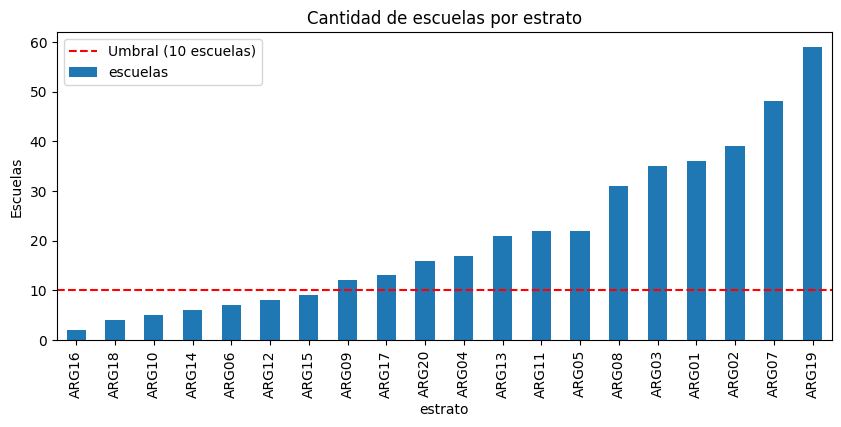

In [15]:
import matplotlib.pyplot as plt

tabla_estratos["escuelas"].plot(kind="bar", figsize=(10, 4))
plt.axhline(10, color="red", linestyle="--", label="Umbral (10 escuelas)")
plt.title("Cantidad de escuelas por estrato")
plt.ylabel("Escuelas")
plt.legend()
plt.show()

**Resultado:** los 20 estratos suman 412 escuelas, pero estan muy desparejos: van de 2
escuelas (ARG16) a 59 (ARG19). Los 7 estratos con menos de 10 escuelas aportan en
conjunto solo 41 escuelas, alrededor del 10% del total.

**Observacion:** los estratos chicos tienen pocos estudiantes en total (ARG16 tiene
37), por lo que sus promedios dependen de muy pocas escuelas y son poco estables.
Este dato justifica el umbral de 10 escuelas usado a continuacion.

**Creacion de la bandera `estrato_fragil`**

In [16]:
# Marca cada estudiante segun el estrato al que pertenece
df["estrato_fragil"] = df["estrato"].map(tabla_estratos["escuelas"]) < UMBRAL_ESCUELAS

df["estrato_fragil"].value_counts()

estrato_fragil
False    10021
True      1071
Name: count, dtype: int64

**Chequeo (Cuales son los estratos 'fragiles')**

In [17]:
fragiles = tabla_estratos[tabla_estratos["escuelas"] < UMBRAL_ESCUELAS]
print("Estratos fragiles:", len(fragiles), "de", len(tabla_estratos))
print(list(fragiles.index))

Estratos fragiles: 7 de 20
['ARG16', 'ARG18', 'ARG10', 'ARG14', 'ARG06', 'ARG12', 'ARG15']


**Resultado:** 7 de los 20 estratos quedan marcados como fragiles: ARG16 (2 escuelas),
ARG18 (4), ARG10 (5), ARG14 (6), ARG06 (7), ARG12 (8) y ARG15 (9).

**Uso:** en el boxplot y en la tabla del dashboard se muestra la cantidad de escuelas
de cada estrato y se advierte cuando es fragil.

**Limitacion:** el umbral es arbitrario. Con 5 quedarian marcados solo 2 estratos y
con 15 quedarian 9 por ello se busco un balance.

## Paso 4: Exportacion

Se guarda el dataset procesado en un archivo nuevo. El archivo original no se
modifica.

In [18]:
df.to_csv("Dataset_procesado.csv", index=False, sep=";")

# Chequeo: leer el archivo guardado y ver que coincide
df_check = pd.read_csv("Dataset_procesado.csv", sep=";")
print("Filas y columnas:", df_check.shape)
print("Columnas:", list(df_check.columns))

Filas y columnas: (11092, 12)
Columnas: ['pais', 'estrato', 'id_escuela', 'id_estudiante', 'peso', 'nse', 'matematica', 'lectura', 'gestion', 'bajo_nivel2', 'tercil_nse', 'estrato_fragil']


### Cifras de referencia para el dashboard

Se calculan los valores principales que muestra el dashboard, para poder verificar
que coinciden. Son promedios ponderados: cada puntaje se multiplica por el peso del
estudiante, se suma todo y se divide por la suma de los pesos.

In [19]:
# Cada puntaje multiplicado por el peso del estudiante
mat_x_peso = df["matematica"] * df["peso"]
lec_x_peso = df["lectura"] * df["peso"]

In [20]:
prom_mat = mat_x_peso.sum() / df["peso"].sum()
prom_lec = lec_x_peso.sum() / df["peso"].sum()

print("Promedio matematica:", round(prom_mat, 1))
print("Promedio lectura:", round(prom_lec, 1))

Promedio matematica: 367.0
Promedio lectura: 388.7


In [21]:
# Suma de (puntaje x peso) y suma de pesos dentro de cada tercil
mat_tercil = mat_x_peso.groupby(df["tercil_nse"], observed=True).sum() / df["peso"].groupby(df["tercil_nse"], observed=True).sum()
lec_tercil = lec_x_peso.groupby(df["tercil_nse"], observed=True).sum() / df["peso"].groupby(df["tercil_nse"], observed=True).sum()

mat_tercil

tercil_nse
Bajo     346.23103
Medio    365.02774
Alto     417.18295
dtype: float64

In [22]:
print("Matematica -> bajo:", round(mat_tercil["Bajo"], 1), "| alto:", round(mat_tercil["Alto"], 1),
      "| brecha:", round(mat_tercil["Alto"] - mat_tercil["Bajo"], 1))
print("Lectura    -> bajo:", round(lec_tercil["Bajo"], 1), "| alto:", round(lec_tercil["Alto"], 1),
      "| brecha:", round(lec_tercil["Alto"] - lec_tercil["Bajo"], 1))

Matematica -> bajo: 346.2 | alto: 417.2 | brecha: 71.0
Lectura    -> bajo: 367.1 | alto: 436.6 | brecha: 69.5


In [23]:
pct_bajo_nivel2 = (df["bajo_nivel2"] * df["peso"]).sum() / df["peso"].sum() * 100
print(f"% bajo Nivel 2 en matematica (ponderado): {pct_bajo_nivel2:.1f}%")

% bajo Nivel 2 en matematica (ponderado): 75.9%


**Resultado:** el dashboard debe mostrar estos valores.

| | Matematica | Lectura |
|---|---|---|
| Promedio nacional | 367,0 | 388,7 |
| Tercil Bajo | 346,2 | 367,1 |
| Tercil Alto | 417,2 | 436,6 |
| Brecha | 71,0 | 69,5 |

Bajo Nivel 2 en matematica: 75,9%.

### Cifras de referencia adicionales

Otro valor que calcula el dashboard: el rango de promedios por estrato, que aparece en
la tercera frase del resumen.

In [24]:
peso_estrato = df["peso"].groupby(df["estrato"]).sum()
mat_estrato = mat_x_peso.groupby(df["estrato"]).sum() / peso_estrato
lec_estrato = lec_x_peso.groupby(df["estrato"]).sum() / peso_estrato

# Estratos con suficientes escuelas (se excluyen las fragiles)
fragil = df.groupby("estrato")["estrato_fragil"].first()
print("Matematica: de", round(mat_estrato[~fragil].min()), "a", round(mat_estrato[~fragil].max()))
print("Lectura: de", round(lec_estrato[~fragil].min()), "a", round(lec_estrato[~fragil].max()))

Matematica: de 312 a 446
Lectura: de 337 a 457


**Resultado:** entre los estratos con suficientes escuelas, el promedio va de 312 a
446 en matematica y de 337 a 457 en lectura.

## Limitaciones y supuestos

- `gestion` es una variable sintetica (asignacion aleatoria) y no permite sacar
  conclusiones sobre escuelas publicas y privadas.
- Se usa un solo valor plausible (`PV1MATH`, `PV1READ`), por lo que los resultados son
  estimaciones puntuales sin error de muestreo.
- El umbral de Nivel 2 (420 puntos) es un valor de referencia aproximado.
- Los terciles de NSE no estan ponderados y 11,6% de los estudiantes no tiene dato de NSE.


**Alcance de las materias:** el dashboard permite analizar matematica y lectura. El
analisis de equidad (relacion con el NSE) y el ranking por estrato funcionan para
ambas. El unico indicador exclusivo de matematica es el porcentaje bajo Nivel 2,
porque se definio con el umbral de esa materia. En esta muestra, la brecha
socioeconomica entre el grupo Alto y el Bajo es similar en las dos materias: 71,0 
puntos en matematica y 69,5 en lectura (promedios ponderados)